# Proyecto Integrador - Avance 1: EDA y Regresion Logistica baseline
FinanceGuard es un banco digital que ha experimentado un crecimiento exponencial en los últimos años, alcanzando 10000 clientes. Sin embargo, la dirección ha detectado un incremento preocupante en la tasa de abandono de clientes (churn), que actualmente alcanza el 20% anual, resultando en pérdidas millonarias.

# Qué es el churn bancario
El churn bancario (o fuga de clientes) ocurre cuando un usuario cancela sus cuentas o deja de usar los servicios de un banco. Para el sector financiero, predecir el churn es crucial porque adquirir un cliente nuevo cuesta entre 5 y 25 veces más que retener a uno actual.

# Pasos a seguir
1. Preparación del entorno
2. Carga y exploración inicial del dataset
3. Análisis de desbalanceo de clases (80/20)
4. Preparación de datos para regresión logística
5. Regresión logística e interpretación de parámetros
6. Evaluación del modelo en el conjunto de prueba (test)
7. Conclusión y próximos pasos


# 1 - Preparación del entorno

Importar las librerías de manipulación de datos (pandas, numpy), visualización (matplotlib, seaborn), modelado (scikit-learn) e inferencia estadística (statsmodels).

In [1]:
import numpy as np              #calculo numerico
import pandas as pd             # manejar tablas
import matplotlib.pyplot as plt #graficos
import seaborn as sns           # graficos
import statsmodels.api as sm    # intervalo de confianza
from matplotlib.colors import LogNorm   #Para arreglar el contraste de color en gráficos
from statsmodels.stats.outliers_influence import variance_inflation_factor

# scikit-learn
# herramientas de preprocesamiento, el modelo y las metricas de evaluacion.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                              roc_curve, roc_auc_score,
                              classification_report, accuracy_score)

RANDOM_STATE = 42 # aseguras que la división de los datos sea reproducible.


# 2 - Carga y exploración inicial del dataset


Cargamos el archivo CSV: *Churn_Modelling.csv*
Verificamos que los datos esten completos, son en total 10,000 filas.

In [2]:
# Cargar el archivo CSV
df = pd.read_csv("./Churn_Modelling.csv", encoding='UTF-8')
print("\033[1m\033[4mCantidad de Filas y columnas:\033[0m", df.shape)
print("\033[1m\033[4mInformacion\033[0m")
display(df.head())
print("\033[1m\033[4mValores nulos por columna\033[0m")
print(df.isnull().sum())
df.head()

Cantidad de Filas y columnas: (10000, 14)
Informacion


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Valores nulos por columna
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


##  Analisis de los valores

| Tipo de Variable | Nombre de la Columna | Descripción / Propósito en el Modelo |
| :--- | :--- | :--- |
| **Identificadores (Sin información)** | `RowNumber`, `CustomerId`, `Surname` | Datos administrativos. No describen comportamiento y deben eliminarse antes de entrenar el modelo. |
| **Variables Demográficas** | `Geography`, `Gender`, `Age` | Describen el perfil personal, región y ciclo de vida del cliente. |
| **Variables Financieras** | `CreditScore`, `Tenure`, `Balance`, `NumOfProducts`, `HasCrCard`, `EstimatedSalary` | Indican el comportamiento económico, antigüedad, productos contratados y salud financiera en el banco. |
| **Variable Objetivo (Target)** | `Exited` | Variable binaria a predecir: **1** si el cliente abandonó el banco y **0** si permanece activo. |


# 3 - Análisis de desbalanceo de clases (80/20)

El desbalance de clases ocurre cuando un conjunto de datos tiene una categoría o clase con muchas más observaciones que las demás.

Exited es nuestra variable objetivo (target) 
- 1 si el cliente abandono el banco
- 0 si sigue activo.

Realizaremos un gráfico de barras, para determinar cuan desbalanceado están los datos

,Clientes,Porcentaje (%)
Activo (0),7963,79.63
Abandono (1),2037,20.37


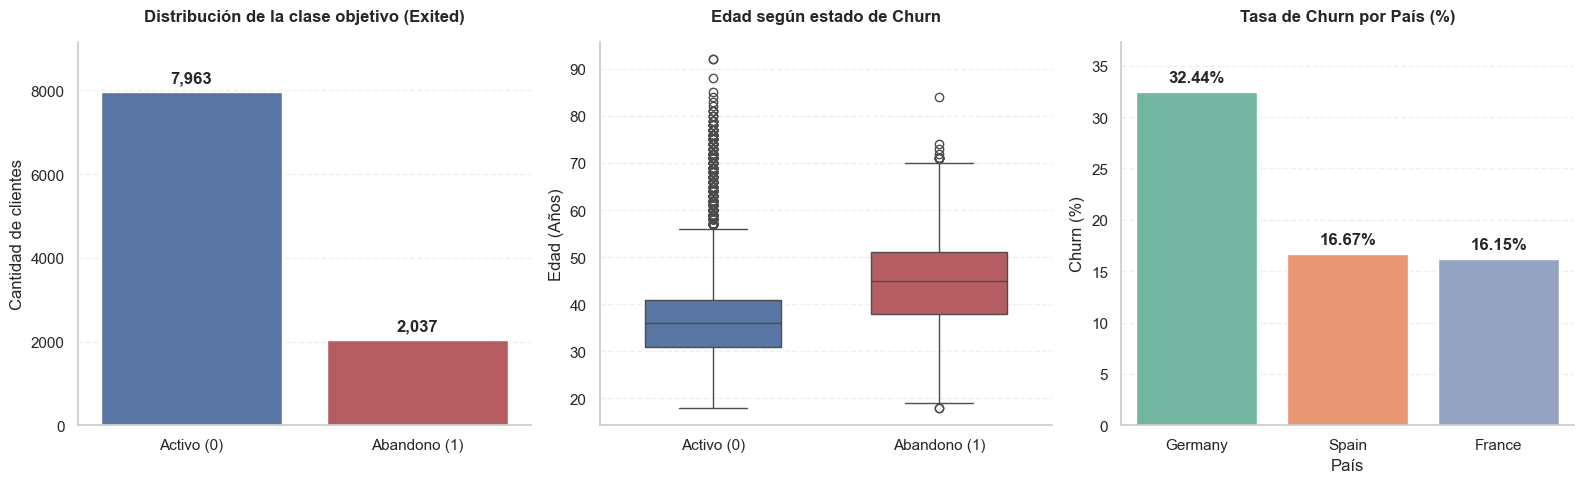

In [3]:

# --- Configuración estética global ---
sns.set_theme(style="white")  # Fondo limpio y blanco
plt.rcParams["font.sans-serif"] = "Arial"  # Tipografía limpia
plt.rcParams["font.family"] = "sans-serif"

# --- Tu código de resumen previo ---
churn_counts = df["Exited"].value_counts()
churn_pct = (df["Exited"].value_counts(normalize=True) * 100).round(2)
resumen_clases = pd.DataFrame({"Clientes": churn_counts, "Porcentaje (%)": churn_pct})
resumen_clases.index = ["Activo (0)", "Abandono (1)"]
display(resumen_clases)

# --- Creación de los gráficos ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # Un poco más alto para mejor proporción

# Palette consistente para estado de churn
churn_palette = ["#4C72B0", "#C44E52"]

# 1. Distribución de la clase objetivo
sns.countplot(
    x="Exited",
    data=df,
    hue="Exited",
    palette=churn_palette,
    legend=False,
    ax=axes[0],
)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Activo (0)", "Abandono (1)"])
axes[0].set_title("Distribución de la clase objetivo (Exited)", pad=15, weight="bold")
axes[0].set_ylabel("Cantidad de clientes")
axes[0].set_xlabel("")

# Agregar etiquetas de datos formateadas con separador de miles
for container in axes[0].containers:
    axes[0].bar_label(container, padding=5, fmt="{:,.0f}", weight="semibold")

# 2. Edad según estado de Churn
sns.boxplot(
    x="Exited",
    y="Age",
    data=df,
    hue="Exited",
    palette=churn_palette,
    legend=False,
    ax=axes[1],
    width=0.6,
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Activo (0)", "Abandono (1)"])
axes[1].set_title("Edad según estado de Churn", pad=15, weight="bold")
axes[1].set_ylabel("Edad (Años)")
axes[1].set_xlabel("")

# 3. Tasa de Churn por País
tasa_pais = df.groupby("Geography")["Exited"].mean().sort_values(ascending=False) * 100
sns.barplot(
    x=tasa_pais.index,
    y=tasa_pais.values,
    hue=tasa_pais.index,
    palette="Set2",
    legend=False,
    ax=axes[2],
)
axes[2].set_title("Tasa de Churn por País (%)", pad=15, weight="bold")
axes[2].set_ylabel("Churn (%)")
axes[2].set_xlabel("País")

# Agregar etiquetas con formato de porcentaje
for container in axes[2].containers:
    axes[2].bar_label(container, padding=5, fmt="%.2f%%", weight="semibold")

# --- Optimización visual en todos los subplots ---
for ax in axes:
    ax.spines["top"].set_visible(False)  # Quitar borde superior
    ax.spines["right"].set_visible(False)  # Quitar borde derecho
    ax.spines["left"].set_color("#cccccc")  # Suavizar borde izquierdo
    ax.spines["bottom"].set_color("#cccccc")  # Suavizar borde inferior
    ax.yaxis.grid(True, linestyle="--", alpha=0.5, color="#e0e0e0")  # Cuadrícula horizontal sutil
    ax.set_axisbelow(True)  # Pasar la cuadrícula al fondo de las barras

# Ajustar márgenes para que las etiquetas superiores no se corten
axes[0].set_ylim(0, df["Exited"].value_counts().max() * 1.15)
axes[2].set_ylim(0, tasa_pais.max() * 1.15)

plt.tight_layout()
plt.show()


>Se observa un fuerte desbalanceo de clases (80% activos vs. 20% abandonos), lo que anticipa la necesidad de evaluar métricas globales como ROC-AUC sobre el accuracy en la regresión logística. Además, se identifican claros patrones predictores: los clientes que abandonan presentan una distribución de edad notablemente más avanzada (mediana cercana a los 45 años frente a ~37 de los activos) y la tasa de churn en Alemania (32.44%) duplica a la de España y Francia. Estos contrastes justifican la inclusión de la edad y la geografía como variables independientes de alto peso en el modelo predictivo.

# 4 - Preparación de datos para regresión logística

## A) Tratamiento de columnas

### Eliminamos las columnas que no aportan informacion
- RowNumber, CustomerId, Surname,  no describen comportamiento, estas columnas serán eliminadas (drop) del modelo 

In [4]:
# repasamos las columnas que disponemos
df.head()
# dropeamos las columnas que no describen comportamiento
df_model = df.drop(columns=["RowNumber"])
df_model = df_model.drop(columns=["CustomerId"])
df_model = df_model.drop(columns=["Surname"])

df_model.head()


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Encoding de variables categóricas (One-Hot, Label Encoding)
- Cuando transformamos una columna categorica en varias columnas, se crea una columna por cada categoría. Si dejas todas las columnas, una de ellas se vuelve totalmente redundante porque su valor se puede deducir de las demás.

- Al activar **drop_first=True**, pandas elimina la primera categoría numéricamente/alfabéticamente, dejándola como la "base de referencia" (France para `Geography`, Female para `Gender`: los odds ratios de `Geography_Germany`, `Geography_Spain` y `Gender_Male` se leen contra esas categorías).

- Con **dtype=int** las columnas nuevas quedan como 0/1. Desde pandas 2.0 el valor por defecto es booleano (True/False), lo que puede dar errores de tipo en `statsmodels` y deja `True/False` en el CSV exportado.

### Analizamos la columna categórica Geography:
- **Geography**: Analizando los valores de esta columna, vemos que son solo **3 posibles valores**, por ende podemos transformarla en 2 columnas de 0/1, en este caso en lugar de generar 3 columnas, una por cada pais se generan 2, una fila que tiene ambas columnas en falso implica que el verdadero en la columna que no se agrego.

In [5]:
# en la columna Geography, hay solo 3 valores posibles, France , Germany y  Spain
df_model = pd.get_dummies(df_model, columns=["Geography"], drop_first=True, dtype=int)
df_model.head()


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,Female,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,Female,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,Female,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,Female,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,Female,43,2,125510.82,1,1,1,79084.10,0,0,1



### Analizamos la columna categórica Gender:
- **Gender**: Analizando los valores de esta columna, vemos que son solo **2 posibles valores**, por ende podemos transformarla en 1 columna de 0/1

In [6]:
df_model = pd.get_dummies(df_model, columns=["Gender"], drop_first=True, dtype=int)
df_model.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


### Descargaremos el DataFrame resultante

In [7]:
# Guarda el DataFrame en un archivo llamado 'df_model.csv'
df_model.to_csv("./Churn_Modelling_limpio.csv", encoding='UTF-8', index=False)

## B) Split básico: train (80%), test (20%)

### División en Predictoras (\[X\]) y Objetivo (\[y\])

separar los datos según el rol que juegan en la predicción: 

**[X] (Variables predictoras o características):** Son los datos de entrada, las pistas o las columnas que el modelo va a analizar para aprender. Se usa la mayúscula (\[X\]) porque suele ser una matriz (una tabla con muchas columnas). 

**[y] (Variable objetivo o target):** Es lo que quieres predecir, el resultado final o la respuesta correcta. Se usa la minúscula (\[y\]) porque suele ser una sola columna (un vector).

**En nuestro modelo:**
    [X] (Variables predictoras o características): todas las columnas menos Exited
    [y] (Variable objetivo o target): Exited

para la división de datos utilizando la librería scikit-learn, con estos parametros:
- X, y: los datos que modelo. 
- test_size=0.2: Indica que el 20% de los datos se reservará para el conjunto de prueba (X_test e y_test), mientras que el 80% restante se destinará de forma automática al conjunto de entrenamiento (X_train e y_train).
- random_state=RANDOM_STATE: Es una "semilla" de aleatoriedad. Al asignarle una variable o un número fijo (como 42), aseguras que la división de los datos sea reproducible. Cada vez que corras el código, los datos se mezclarán exactamente de la misma manera, evitando que los resultados de tu modelo cambien por puro azar.
- stratify=y:  Fuerza a que la división mantenga la misma proporción de clases en el conjunto de entrenamiento y en el de prueba que la que existe en el dataset original (y).

In [8]:
X = df_model.drop(columns=["Exited"])       # todos menos Exited
y = df_model["Exited"]                      # Exited

# para la división de datos utilizando la librería scikit-learn 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y    
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (8000, 11)  Test: (2000, 11)


## C) Escalamiento de variables numericas
Escalamos solo las variables **continuas**. Las binarias (`HasCrCard`, `IsActiveMember`, `Geography_*`, `Gender_Male`) se dejan en 0/1, así su odds ratio se interpreta como el cambio de pasar de 0 a 1. Para las continuas, el odds ratio es **por cada +1 desvío estándar**.

 Usamos **StandardScaler**, que transforma cada variable para que tenga media 0 y desvio estandar 1. Ajustamos (fit) el scaler solo con datos de entrenamiento y lo aplicamos (transform) a ambos conjuntos, para no filtrar informacion del test al entrenamiento (data leakage).

In [9]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]   # solo continuas

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
2151,1.058568,1.715086,0.684723,-1.226059,-0.910256,1,0,1.042084,0,0,1
8392,0.913626,-0.659935,-0.696202,0.413288,-0.910256,1,0,-0.623556,1,0,1
5006,1.079274,-0.184931,-1.731895,0.601687,0.808830,1,1,0.308128,1,0,0
4117,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,1,0,-0.290199,0,0,1
7182,0.427035,0.955079,0.339492,0.548318,0.808830,0,1,0.135042,1,0,1


## D) Diagnóstico de multicolinealidad (Correlación y VIF)

La multicolinealidad ocurre cuando dos o mas variables predictoras estan muy correlacionadas entre si, lo que puede hacer inestables los coeficientes de la regresion logistica. Miramos rapidamente la matriz de correlacion de las variables numericas (calculada solo sobre train, para no mirar el test todavia) para detectar algun par sospechoso (valores cercanos a 1 o -1).

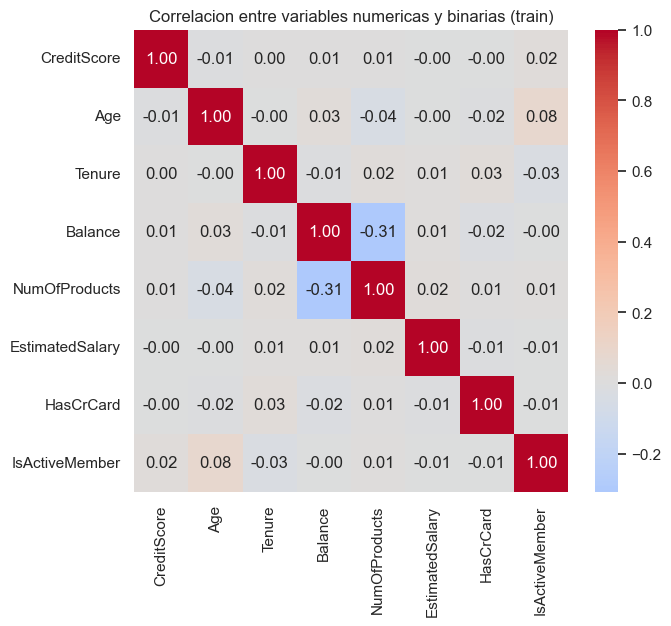

,Variable,VIF
0,Geography_Germany,1.34
1,Balance,1.34
2,Geography_Spain,1.13
3,NumOfProducts,1.13
4,Age,1.01
5,IsActiveMember,1.01
6,Gender_Male,1.00
7,Tenure,1.00
8,HasCrCard,1.00
9,EstimatedSalary,1.00


In [10]:
corr_cols = num_cols + ["HasCrCard", "IsActiveMember"]
corr = X_train[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlacion entre variables numericas y binarias (train)")
plt.show()

X_vif = sm.add_constant(X_train_scaled.astype(float))
vif_df = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).query("Variable != 'const'").sort_values("VIF", ascending=False).reset_index(drop=True)

display(vif_df.round(2))

>Los VIF están todos por debajo de 1,4 (los más altos: `Balance` y `Geography_Germany`, con 1,34). Esa asociación es esperable: ningún cliente alemán tiene saldo cero y su saldo medio es el doble que el de Francia y España. Con el criterio habitual (VIF > 5 o 10 indica un problema), **no hay multicolinealidad relevante** y los coeficientes del modelo son estables. No hace falta eliminar ninguna variable.


# 5 - Regresión Logística e interpretación de parámetros

## Regresion Logistica con scikit-learn

La regresión logística es un método estadístico y de aprendizaje automático que sirve para calcular la probabilidad de que ocurra un evento que tiene solo dos resultados posibles (por ejemplo, sí o no, Abandona o se queda, aprobado o reprobado). Es **simple** cuando usa una sola variable predictora y **múltiple** cuando usa varias; en este proyecto es múltiple (10 variables predictoras)

**Scikit-learn** es considerado uno de los frameworks más simples y amigables para implementar aprendizaje automático en Python

## A) La funcion sigmoide
La función sigmoide es el puente matemático que transforma una ecuación de línea recta en una probabilidad entre 0 y 1. Sin ella, la regresión logística simplemente no podría funcionar para clasificar datos.
Cuando calculas una regresión (como la lineal), la fórmula matemática te puede devolver cualquier número: desde valores muy negativos como -500 hasta valores muy altos como 12,500.El problema es que una probabilidad no puede ser menor que 0% ni mayor que 100%. Ahí es donde entra la función sigmoide.

La **funcion sigmoide** toma cualquier número infinito **(z)** y lo "aplasta" dentro de un rango estrictamente limitado entre **0 y 1**

**La regresion logistica no predice directamente 0 o 1:** calcula una combinacion lineal de las variables y la pasa por la funcion sigmoide, que "aplasta" cualquier numero real al rango (0, 1), interpretable como una probabilidad de que el cliente abandone.

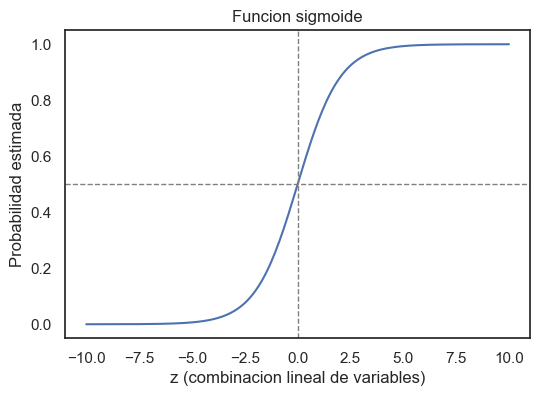

In [11]:
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(z, sigmoid, color="#4C72B0")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("z (combinacion lineal de variables)")
ax.set_ylabel("Probabilidad estimada")
ax.set_title("Funcion sigmoide")
plt.show()

## B) Entrenamiento del modelo baseline y análisis de Odds Ratios con Intervalos de Confianza
Nos sirve para interpretar el modelo y descubrir cuáles son las variables más importantes para predecir el resultado. 
Lo que hace es crear una tabla ordenada que te muestra el impacto real, la dirección y la fuerza que tiene cada una de tus variables predictoras.

In [12]:
log_reg = LogisticRegression(C=np.inf, random_state=RANDOM_STATE, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
X_train_sm = sm.add_constant(X_train_scaled.astype(float), has_constant="add")
logit_sm = sm.Logit(y_train.astype(float), X_train_sm).fit(disp=False)
ci = logit_sm.conf_int()

tabla_odds = pd.DataFrame({
    "Variable": logit_sm.params.index,
    "Coeficiente (log-odds)": logit_sm.params.values,
    "Odds_Ratio": np.exp(logit_sm.params.values),
    "IC_95_inf": np.exp(ci[0].values),
    "IC_95_sup": np.exp(ci[1].values),
    "p_valor": logit_sm.pvalues.values,
}).query("Variable != 'const'").sort_values("Odds_Ratio", ascending=False).reset_index(drop=True)

display(tabla_odds.round(3))

,Variable,Coeficiente (log-odds),Odds_Ratio,IC_95_inf,IC_95_sup,p_valor
0,Geography_Germany,0.825,2.281,1.967,2.645,0.000
1,Age,0.740,2.095,1.976,2.222,0.000
2,Balance,0.160,1.174,1.094,1.260,0.000
3,EstimatedSalary,0.048,1.049,0.988,1.113,0.116
4,Geography_Spain,0.045,1.046,0.896,1.220,0.570
5,Tenure,-0.020,0.980,0.924,1.040,0.504
6,NumOfProducts,-0.071,0.932,0.877,0.990,0.022
7,HasCrCard,-0.071,0.931,0.818,1.061,0.284
8,CreditScore,-0.086,0.918,0.865,0.974,0.004
9,Gender_Male,-0.525,0.592,0.525,0.667,0.000


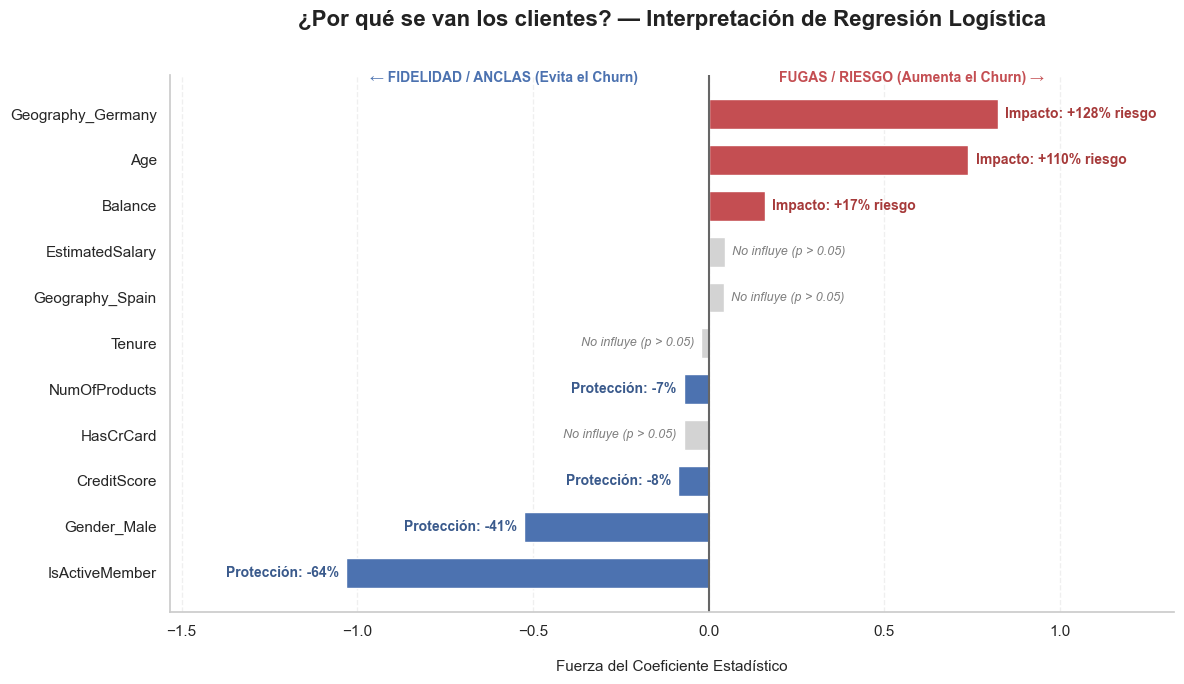

In [26]:
# 1. Cargar tus datos reales ordenados de mayor a menor coeficiente
df = pd.DataFrame(tabla_odds).sort_values(
    by="Coeficiente (log-odds)", ascending=True
)  # Ascending=True para que las rojas queden arriba y coincidan con el orden visual de barh

# 2. Configuración estética global
sns.set_theme(style="white")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(12, 7))

# Asignación de colores inteligente según p-valor y signo
colores = []
for _, row in df.iterrows():
    if row["p_valor"] > 0.05:
        colores.append("#d3d3d3")  # Gris sutil para variables no significativas
    elif row["Coeficiente (log-odds)"] > 0:
        colores.append("#C44E52")  # Rojo Riesgo
    else:
        colores.append("#4C72B0")  # Azul Retención

# 3. Dibujar las barras horizontales
bars = ax.barh(df["Variable"], df["Coeficiente (log-odds)"], color=colores, height=0.65)

# Línea divisoria central en cero
ax.axvline(x=0, color="#666666", linestyle="-", linewidth=1.5)

# 4. DINÁMICA DE ETIQUETAS BLINDADA (Calculada directamente desde la geometría del gráfico)
for i, bar in enumerate(bars):
    # Extraemos el valor exacto que tiene la barra dibujada en el eje X
    width = bar.get_width()
    row = df.iloc[i]
    p_val = row["p_valor"]

    # VARIABLES NO SIGNIFICATIVAS
    if p_val > 0.05:
        align_x = width + 0.02 if width >= 0 else width - 0.02
        align_h = "left" if width >= 0 else "right"
        ax.text(
            align_x,
            bar.get_y() + bar.get_height() / 2,
            "No influye (p > 0.05)",
            va="center",
            ha=align_h,
            style="italic",
            color="#7f7f7f",
            fontsize=9,
        )

    # VARIABLES SIGNIFICATIVAS POSITIVAS (Riesgo / Barras Rojas)
    elif width >= 0:
        # Matemática: (e^coeficiente - 1) * 100
        porcentaje_riesgo = int(round((np.exp(width) - 1) * 100))
        ax.text(
            width + 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"Impacto: +{porcentaje_riesgo}% riesgo",
            va="center",
            ha="left",
            weight="bold",
            color="#A63A3A",
            fontsize=10,
        )

    # VARIABLES SIGNIFICATIVAS NEGATIVAS (Protección / Barras Azules)
    else:
        # Matemática: (1 - e^coeficiente) * 100
        porcentaje_proteccion = int(round((1 - np.exp(width)) * 100))
        ax.text(
            width - 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"Protección: -{porcentaje_proteccion}%",
            va="center",
            ha="right",
            weight="bold",
            color="#3A5A8C",
            fontsize=10,
        )


# 5. Ajustes finales de estructura, títulos y límites
ax.set_title(
    "¿Por qué se van los clientes? — Interpretación de Regresión Logística",
    pad=35,
    weight="bold",
    fontsize=16,
    color="#222222",
)
ax.set_xlabel("Fuerza del Coeficiente Estadístico", labelpad=15, fontsize=11)

# Dinamismo en los límites horizontales para que no se corten los textos largos
ax.set_xlim(
    df["Coeficiente (log-odds)"].min() - 0.5,
    df["Coeficiente (log-odds)"].max() + 0.5,
)

# Ocultar espinas y activar cuadrícula vertical sutil
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#cccccc")
ax.spines["left"].set_color("#cccccc")
ax.xaxis.grid(True, linestyle="--", alpha=0.3, color="#cccccc")
ax.set_axisbelow(True)

# CORRECCIÓN DE POSICIÓN DE TEXTOS GUÍA (Flotan de forma segura arriba del gráfico)
posicion_y_superior = len(df) - 0.3
ax.text(
    0.2,
    posicion_y_superior,
    "FUGAS / RIESGO (Aumenta el Churn) →",
    color="#C44E52",
    weight="bold",
    fontsize=10,
    ha="left",
)
ax.text(
    -0.2,
    posicion_y_superior,
    "← FIDELIDAD / ANCLAS (Evita el Churn)",
    color="#4C72B0",
    weight="bold",
    fontsize=10,
    ha="right",
)

plt.tight_layout()
plt.show()


- Si el p-valor es MENOR a 0.05 (\(p < 0.05\)): La variable es Estadísticamente Significativa. Hay menos de un 5% de probabilidades de que el resultado sea una coincidencia. El impacto es real. 
- Si el p-valor es MAYOR a 0.05 (\(p > 0.05\)): La variable No es Significativa. El riesgo de que el resultado sea pura casualidad es muy alto. Por lo tanto, el modelo la descarta y pintamos la barra de gris.


## C) Impacto de las Variables en el Modelo (Odds Ratios)

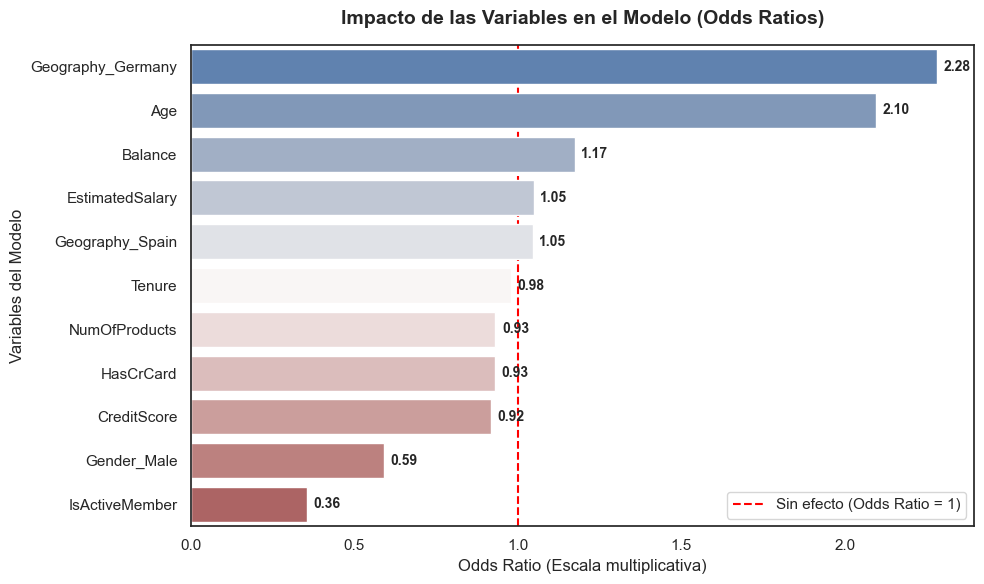

In [28]:

plt.figure(figsize=(10, 6))

# 1. Línea de referencia crucial en 1 (La dibujamos PRIMERO para que quede al fondo)
plt.axvline(x=1, color="red", linestyle="--", linewidth=1.5, label="Sin efecto (Odds Ratio = 1)", zorder=1)

# 2. Creamos el gráfico usando los nombres exactos de tus columnas (Mayúsculas)
ax = sns.barplot(
    x="Odds_Ratio", 
    y="Variable", 
    hue="Variable",
    data=tabla_odds, 
    palette="vlag",  # Excelente elección de paleta divergente
    legend=False,
    zorder=2         # Hace que las barras queden por encima de la línea de referencia
)

# 3. Recorremos 'tabla_odds' (Corregido) usando los nombres de columnas correctos
for i, fila in tabla_odds.reset_index(drop=True).iterrows():
    ax.text(
        x=fila["Odds_Ratio"] + 0.02,   # Posición X
        y=i,                           # Posición Y
        s=f"{fila['Odds_Ratio']:.2f}", # Texto formateado
        va="center",                   
        ha="left",                     
        fontsize=10,
        weight="bold"                  
    )

# 4. Configuración estética final
plt.title("Impacto de las Variables en el Modelo (Odds Ratios)", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Odds Ratio (Escala multiplicativa)", fontsize=12)
plt.ylabel("Variables del Modelo", fontsize=12)
plt.legend(loc="lower right") # Colocamos la leyenda abajo a la derecha para que no estorbe
plt.tight_layout()
plt.show()




| Valor del Odds Ratio (OR) | Tipo de Impacto | Efecto en el Churn (Exited = 1) | Interpretación Práctica |
| :--- | :--- | :--- | :--- |
| **OR > 1** | 📈 Impacto Positivo | **Aumenta** la probabilidad | Factor de riesgo. En una variable binaria, pasar de 0 a 1 multiplica las posibilidades de abandono por el OR; en una continua escalada, cada +1 desvío estándar las multiplica por el OR. Ejemplo: `Age` con OR ≈ 2,1 significa que, por cada ~10 años más, las posibilidades de abandono se duplican aproximadamente. |
| **OR = 1** | ➖ Impacto Neutro | **No tiene efecto** | Variable irrelevante. No aporta valor predictivo ni altera las posibilidades de abandono. |
| **OR < 1** | 🛡️ Impacto Negativo / Protector | **Disminuye** la probabilidad | Factor de retención. A mayor valor de esta variable, el cliente es más propenso a quedarse en el banco. |

> **Ojo con `NumOfProducts`:** la relación con el churn no es lineal (abandonan el 27,7% con 1 producto, el 7,6% con 2, el 82,7% con 3 y el 100% con 4). Su OR lineal (≈ 0,93) resume mal ese patrón y no debe leerse como "más productos protegen".


## D) Intervalos de confianza

los intervalos de confianza (IC) te dicen qué tan "seguro" está el modelo sobre el impacto real de cada variable en el churn.

In [29]:
# 1. Statsmodels necesita la constante (intercepto) y datos numéricos (float)
X_train_const = sm.add_constant(X_train_scaled.astype(float), has_constant="add")

# 2. Ajustar el modelo (Logit)
modelo_sm = sm.Logit(y_train.astype(float), X_train_const).fit(disp=False)

# 3. Extraer coeficientes e intervalos de confianza al 95%
resumen = modelo_sm.params.to_frame(name="coeficiente")
intervalos = modelo_sm.conf_int(alpha=0.05) # 0.05 = 95% de confianza

# 4. Unir todo y aplicar la exponencial (np.exp) para obtener Odds Ratios
coef_df = resumen.join(intervalos)
coef_df.columns = ["coeficiente", "limite_inferior_coef", "limite_superior_coef"]

# Transformar a Odds Ratios humanos
coef_df["odds_ratio"] = np.exp(coef_df["coeficiente"])
coef_df["OR_limite_inf"] = np.exp(coef_df["limite_inferior_coef"])
coef_df["OR_limite_sup"] = np.exp(coef_df["limite_superior_coef"])
coef_df["Margen"] = coef_df["OR_limite_sup"] - coef_df["OR_limite_inf"]            # ancho absoluto (crece con el OR)
coef_df["Amplitud_log"] = np.log(coef_df["OR_limite_sup"] / coef_df["OR_limite_inf"])  # ancho relativo, comparable entre variables

# Ordenar por el Margen
coef_df = coef_df[["odds_ratio", "OR_limite_inf", "OR_limite_sup", "Margen", "Amplitud_log"]].sort_values("Margen", ascending=True)
coef_df.round(3)


,odds_ratio,OR_limite_inf,OR_limite_sup,Margen,Amplitud_log
IsActiveMember,0.356,0.314,0.404,0.090,0.251
CreditScore,0.918,0.865,0.974,0.109,0.118
const,0.370,0.319,0.429,0.110,0.298
NumOfProducts,0.932,0.877,0.990,0.112,0.121
Tenure,0.980,0.924,1.040,0.116,0.118
EstimatedSalary,1.049,0.988,1.113,0.125,0.119
Gender_Male,0.592,0.525,0.667,0.141,0.238
Balance,1.174,1.094,1.260,0.166,0.141
HasCrCard,0.931,0.818,1.061,0.243,0.260
Age,2.095,1.976,2.222,0.246,0.117


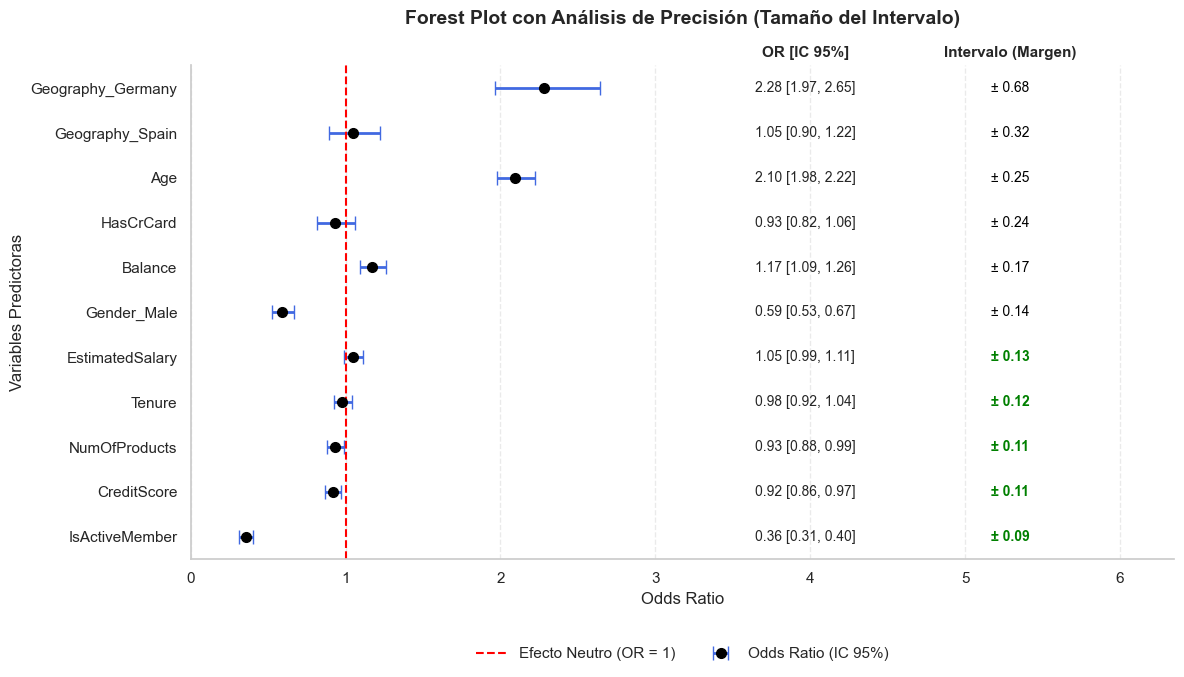

In [30]:
# 1. Limpieza y orden de datos (eliminamos el intercepto constante)
df_grafico = coef_df.drop(index="const", errors="ignore").copy()

# Ordenamos de menor a mayor Margen (las de ALTA PRECISIÓN quedarán arriba)
df_grafico = df_grafico.sort_values("Margen", ascending=True)

# 2. Configurar el lienzo con espacio extra a la derecha para el texto
fig, ax = plt.subplots(figsize=(12, 7))

# Calcular distancias asimétricas para las barras de error
error_izquierdo = df_grafico["odds_ratio"] - df_grafico["OR_limite_inf"]
error_derecho = df_grafico["OR_limite_sup"] - df_grafico["odds_ratio"]
errores_asimetricos = np.array([error_izquierdo, error_derecho])

# 3. Dibujar el Forest Plot
ax.errorbar(
    x=df_grafico["odds_ratio"], 
    y=range(len(df_grafico)), 
    xerr=errores_asimetricos,
    fmt='o', 
    color='black', 
    ecolor='royalblue', 
    elinewidth=2, 
    capsize=5, 
    markersize=7,
    label="Odds Ratio (IC 95%)"
)

# Ajustar las etiquetas del eje Y con los nombres de tus variables
ax.set_yticks(range(len(df_grafico)))
ax.set_yticklabels(df_grafico.index, fontsize=11)

# Línea vertical de referencia en OR = 1
ax.axvline(x=1, color="red", linestyle="--", linewidth=1.5, label="Efecto Neutro (OR = 1)")

# 4. AGREGAR LA TABLA DE PRECISIÓN A LA DERECHA
limite_derecho_grafico = df_grafico["OR_limite_sup"].max()
posicion_texto_or = limite_derecho_grafico * 1.5
posicion_texto_margen = limite_derecho_grafico * 2.0

# Encabezados de la tabla de texto
posicion_y_encabezados = len(df_grafico) - 0.3
ax.text(posicion_texto_or, posicion_y_encabezados, "OR [IC 95%]", weight="bold", ha="center", fontsize=11)
ax.text(posicion_texto_margen, posicion_y_encabezados, "Intervalo (Margen)", weight="bold", ha="center", fontsize=11)

# Recorremos cada variable para pintar su información analítica
for i, (nombre_var, fila) in enumerate(df_grafico.iterrows()):
    texto_intervalo = f"{fila['odds_ratio']:.2f} [{fila['OR_limite_inf']:.2f}, {fila['OR_limite_sup']:.2f}]"
    ax.text(posicion_texto_or, i, texto_intervalo, ha="center", va="center", fontsize=10)
    
    texto_margen = f"± {fila['Margen']:.2f}"
    
    es_alta_precision = fila["Margen"] < df_grafico["Margen"].median()
    color_texto = "green" if es_alta_precision else "black"
    peso_texto = "bold" if es_alta_precision else "normal"
    
    ax.text(posicion_texto_margen, i, texto_margen, ha="center", va="center", 
            fontsize=10, color=color_texto, weight=peso_texto)

# 5. Formato Final y Límites del gráfico
ax.set_title("Forest Plot con Análisis de Precisión (Tamaño del Intervalo)", fontsize=14, pad=30, weight="bold")
ax.set_xlabel("Odds Ratio", fontsize=12)
ax.set_ylabel("Variables Predictoras", fontsize=12)

# Forzamos al eje X a expandirse para que quepa la tabla de texto a la derecha
ax.set_xlim(0, posicion_texto_margen * 1.2)

# --- MEJORAS ESTÉTICAS Y DE SEÑALIZACIÓN ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")

# Cuadrícula de fondo sutil solo en el eje X para medir la distancia a la línea roja
ax.xaxis.grid(True, linestyle="--", alpha=0.4, color="#cccccc")
ax.set_axisbelow(True)

# LEYENDA REUBICADA (Se centró en X=0.5, se dispuso en formato horizontal con 'ncol=2' y se separó del gráfico con '-0.15')
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    frameon=False,
    fontsize=11
)

plt.tight_layout()
plt.show()

### Interpretación del Intervalo de Confianza

Para validar la robustez de las variables en nuestro modelo de regresión logística, analizamos los intervalos de confianza de los *Odds Ratios* bajo dos dimensiones: **Significancia Estadística** y **Precisión de la Medida**.

---

#### 1. Significancia Estadística (¿El impacto de la variable es real?)

Esta métrica determina si el efecto de la variable es estadísticamente confiable o si podría ser fruto del azar, basándose en si el intervalo incluye o no el valor neutro (`1.0`).

| Caso | Condición del Intervalo | Conclusión del Modelo | Variables del Dataset |
| :--- | :--- | :--- | :--- |
| **Caso 1: Significativa** | **NO incluye el 1.0** | El impacto es real y confiable. No es fruto de la casualidad. | `IsActiveMember`, `CreditScore`, `NumOfProducts`, `Balance`, `Age`, `Geography_Germany`, `Gender_Male` |
| **Caso 2: NO Significativa** | **SÍ incluye el 1.0** | No es confiable. El modelo no sabe si el factor ayuda a retener o a que se vayan. | `Tenure`, `EstimatedSalary`, `Geography_Spain`, `HasCrCard` |

---

#### 2. Amplitud del Intervalo (¿Qué tan preciso es el modelo?)

El ancho absoluto del intervalo (`Margen`) crece con el tamaño del OR, así que no sirve para comparar variables con efectos muy distintos (un OR de 2,3 tendrá siempre un margen mayor que uno de 0,9 aun con la misma precisión). Para comparar usamos la **amplitud logarítmica**, `ln(OR_sup / OR_inf)`, que mide el ancho relativo.

| Nivel de Precisión | Amplitud logarítmica | Significado Práctico | Variables del Dataset |
| :--- | :--- | :--- | :--- |
| **Alta Precisión** *(Estrecho)* | Menor a **0.15** | El modelo estima con mucha certeza la magnitud del efecto. Son las variables continuas, medidas por desvío estándar. | `Age`, `CreditScore`, `Tenure`, `EstimatedSalary`, `NumOfProducts`, `Balance` |
| **Moderada** | Entre **0.15 y 0.35** | Hay más incertidumbre sobre la magnitud. Son las variables binarias, que varían menos y por eso tienen intervalos relativamente más anchos. | `Gender_Male`, `IsActiveMember`, `HasCrCard`, `Geography_Germany`, `Geography_Spain` |

Ninguna variable muestra una precisión baja. `Geography_Germany` tiene el margen absoluto más grande (0,68) porque su efecto es grande (OR ≈ 2,3), no porque falten datos: Alemania representa el 25% de los clientes (2.509).


# 6. Evaluación del modelo en el conjunto de prueba (test)


## A) Matriz de confusión

Con el modelo entrenado, generamos las predicciones sobre el conjunto de test (clase predicha y probabilidad de churn) y empezamos por la matriz de confusion, que compara lo predicho contra lo real.
Nos deja ver, ademas del accuracy, cuantos clientes que si abandonaron el modelo detecto (verdaderos positivos) y cuantos se le escaparon (falsos negativos) - algo critico en churn, donde no detectar a un cliente que se va tiene un costo de negocio directo.

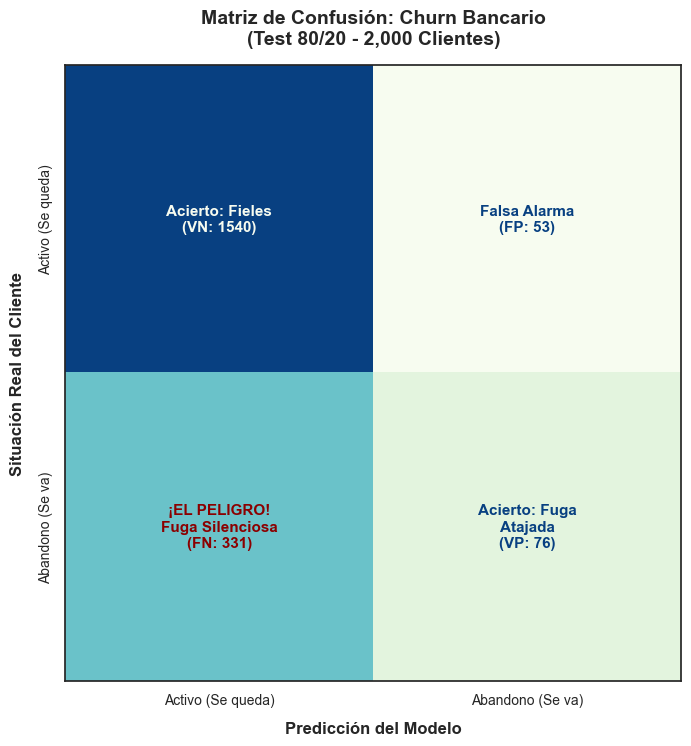

In [31]:
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
# Configurar el Display NATIVO con tus etiquetas comerciales
etiquetas = ["Activo (Se queda)", "Abandono (Se va)"]
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="GnBu", colorbar=False, values_format="d", im_kw={"norm": LogNorm()})
# ==========================================================
# 5. PERSONALIZACIÓN DE TEXTOS INTERNOS (Cruce de Negocio)
# ==========================================================
# Creamos la lista con los  textos exactos en el orden de la matriz:
# [[VN, FP], [FN, VP]]
textos_personalizados = [
    [f"Acierto: Fieles\n(VN: {cm[0,0]})", f"Falsa Alarma\n(FP: {cm[0,1]})"],
    [f"¡EL PELIGRO!\nFuga Silenciosa\n(FN: {cm[1,0]})", f"Acierto: Fuga\nAtajada\n(VP: {cm[1,1]})"]
]

# Recorremos cada cuadro del gráfico para reemplazar el número plano por tu texto
for i in range(2):
    for j in range(2):
        # Seleccionamos el texto que scikit-learn puso por defecto
        texto_celda = disp.text_[i, j]
        # Cambiamos su contenido
        texto_celda.set_text(textos_personalizados[i][j])
        # Ajustamos el tamaño y estilo de la letra interna
        texto_celda.set_fontsize(11)
        texto_celda.set_weight("bold")
        
        # El cuadrante de peligro (FN) lo pintamos con letra roja para que resalte
        if i == 1 and j == 0:
            texto_celda.set_color("darkred")
# ==========================================================
ax.set_title("Matriz de confusion")
plt.xlabel("Predicción del Modelo", fontsize=12, labelpad=10, weight="bold")
plt.ylabel("Situación Real del Cliente", fontsize=12, labelpad=10, weight="bold")
plt.xticks(rotation=0, ha="center", va="center")
plt.yticks(rotation=90, ha="center", va="center")
ax.tick_params(axis='both', which='major', labelsize=10, pad=8)
plt.title("Matriz de Confusión: Churn Bancario\n(Test 80/20 - 2,000 Clientes)", fontsize=14, pad=15, weight="bold")

plt.show()


El rendimiento de las predicciones del modelo frente a la realidad del comportamiento de los clientes se distribuye de la siguiente manera:

| Métrica | Clasificación | Cantidad | Descripción del Resultado | Impacto o Costo de Negocio |
| :--- | :--- | :---: | :--- | :--- |
| **Verdaderos Negativos (VN)** | ¡Acierto! | **1,540** | El modelo predijo que se quedarían y **se quedaron**. | **Alta eficiencia:** Mantenimiento operativo estándar sin gastos extra de retención. |
| **Falsos Positivos (FP)** | Falsa Alarma | **53** | El modelo predijo que se irían, pero **se quedaron**. | **Gasto innecesario:** El banco podría invertir presupuesto en campañas o incentivos para clientes que no planeaban irse. |
| **Falsos Negativos (FN)** | ⚠️ El Peligro | **331** | El modelo predijo que se quedarían, pero **se fueron**. | **Costo crítico:** Es el peor error para el negocio. El cliente se fuga en silencio sin que el banco active alertas o intente retenerlo. |
| **Verdaderos Positivos (VP)** | ¡Acierto! | **76** | El modelo predijo que se irían y **se fueron**. | **Oportunidad de Oro:** Permite al banco reaccionar a tiempo y lanzar estrategias de fidelización dirigidas. |


### Conclusión del Rendimiento Global (Accuracy)

Si consolidamos el balance total de predicciones correctas frente a las desviaciones lógicas del modelo, obtenemos el siguiente escenario estadístico:

#### Desglose de Errores
* **Falsas Alarmas (FP):** 53 clientes.
* **El Peligro / No detectados (FN):** 331 clientes.
* **Total de errores operativos:** 384 clientes de un total de 2,000 evaluados.

#### Desglose de Aciertos
* **Predicciones Correctas (VN + VP):** 1,540 + 76 = 1,616 clientes identificados de manera exacta.

---

### Métrica Final de Ajuste

| Métrica Evaluada | Proporción de Éxito | Porcentaje de Rendimiento | Diagnóstico de Negocio |
| :--- | :---: | :---: | :--- |
| **Exactitud (Accuracy)** | $\frac{1,616}{2,000}$ | **80.8%** | El modelo clasifica de manera correcta a **8 de cada 10 clientes**. Sin embargo, la alta concentración de errores en la categoría de "No detectados" (FN) sugiere la necesidad de ajustar el umbral de decisión para capturar de mejor forma la fuga real de capital. |


## B) Curva ROC y AUC

La curva ROC muestra el trade-off entre detectar correctamente a los clientes que abandonan (recall) y equivocarse marcando como churn a clientes que en realidad se quedan (falsos positivos), a distintos umbrales de decision. El AUC (area bajo la curva) resume esa curva en un solo numero: 0.5 es un modelo que predice al azar, 1.0 es un modelo perfecto.

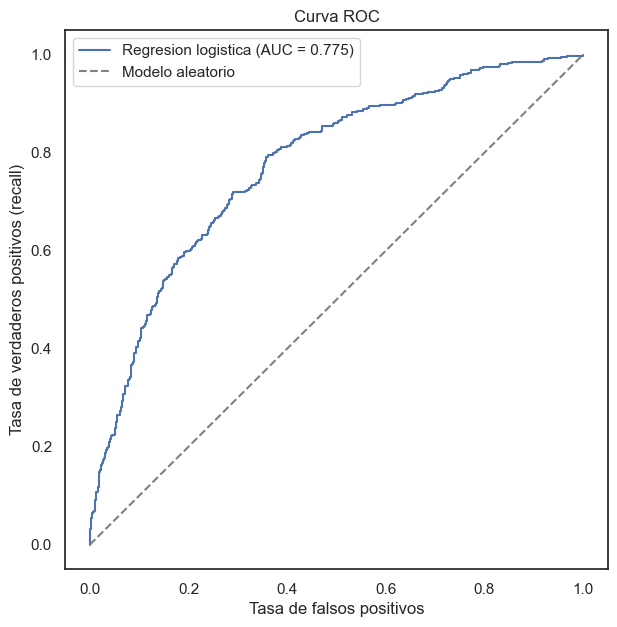

AUC: 0.775


In [32]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(fpr, tpr, color="#4C72B0", label=f"Regresion logistica (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Modelo aleatorio")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curva ROC")
ax.legend()
plt.show()

print(f"AUC: {auc:.3f}")

### Guía de Interpretación del Valor AUC (Área Bajo la Curva ROC)

El valor del AUC indica la capacidad del modelo para distinguir correctamente entre un cliente que abandonará el banco (churn) y uno que permanecerá leal. Su valor va de 0 a 1: 0.5 equivale al azar y, si fuera menor que 0.5, el modelo estaría ordenando al revés (bastaría invertir sus predicciones). En la práctica se interpreta entre 0.5 y 1.0:

| Rango de AUC | Clasificación del Rendimiento | Significado Técnico y de Negocio | Diagnóstico / Acción Requerida |
| :--- | :--- | :--- | :--- |
| **AUC = 0.500** | ❌ Completamente Inútil | El modelo no tiene capacidad de discriminación. Clasifica el churn al azar, equivalente a lanzar una moneda al aire. | **Rechazar:** El modelo no sirve para la operación. |
| **0.500 - 0.600** | ❌ Muy pobre | Apenas mejor que el azar. | **Rechazar o rehacer** el enfoque. |
| **0.600 - 0.700** | ⚠️ Pobre / Regular | El modelo presenta serias dificultades para separar a los clientes leales de los que están en riesgo de fuga. | **Mejorar:** Requiere ingeniería de variables o probar otros algoritmos. |
| **0.700 - 0.800** | 🔄 Bueno / Aceptable | Rendimiento estándar. Es viable para producción, aunque posee margen de mejora. Rango típico de un modelo base inicial. | **Aceptar con reservas:** Útil como punto de partida para estrategias piloto. |
| **0.800 - 0.900** | 🌟 Excelente | Alta capacidad predictiva. Asigna probabilidades elevadas a los clientes reales en fuga y bajas a los clientes estables. | **Aprobar con criterio de negocio:** un AUC alto indica que el modelo ordena bien a los clientes, pero para decidir a quién contactar hay que elegir un umbral según el costo de cada tipo de error. |
| **0.900 - 1.000** | 🚨 Sobresaliente / Alerta | El modelo es casi perfecto separando ambas clases. | **Investigar:** Si el valor supera **0.95**, existe un riesgo crítico de *Data Leakage* (filtración de datos del futuro que hacen "trampa"). |


## C) Precision, Recall, F1-Score




Por el desbalanceo de clases que vimos al principio, el accuracy solo no alcanza para juzgar el modelo. classification_report nos provee, para cada clase, 
- precision (de los que predije como churn, cuantos lo eran realmente), 
- recall (de los que realmente hicieron churn, cuantos detecte) y 
- F1-score (el balance entre ambas).

In [33]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}\n")
reporte_dict = classification_report(
    y_test, 
    y_pred, 
    target_names=["Activo", "Abandono"], 
    output_dict=True  
)
print(classification_report(y_test, y_pred, target_names=["Activo", "Abandono"]))

Accuracy: 0.808

              precision    recall  f1-score   support

      Activo       0.82      0.97      0.89      1593
    Abandono       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



#### Efecto de balancear los pesos de las clases

La conclusión final cita el resultado de la regresión con `class_weight="balanced"`. Lo calculamos acá para que quede documentado: el modelo penaliza más los errores sobre la clase minoritaria (abandono) y, con el mismo umbral de 0.5, detecta muchos más abandonos a costa de más falsas alarmas.


In [34]:
log_reg_bal = LogisticRegression(C=float('inf'), class_weight="balanced",
                                 random_state=RANDOM_STATE, max_iter=1000)
log_reg_bal.fit(X_train_scaled, y_train)

y_pred_bal = log_reg_bal.predict(X_test_scaled)
print(classification_report(y_test, y_pred_bal, target_names=["Activo", "Abandono"]))
print(f"ROC-AUC (balanceado): {roc_auc_score(y_test, log_reg_bal.predict_proba(X_test_scaled)[:, 1]):.3f}")


              precision    recall  f1-score   support

      Activo       0.90      0.72      0.80      1593
    Abandono       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

ROC-AUC (balanceado): 0.777


### Análisis del Reporte de Clasificación por Clase (Recall, Precision y Support)

Al desagregar el rendimiento del modelo para cada tipo de cliente (Activos vs. Abandonos), se hace evidente el impacto del desbalance de datos en nuestras predicciones:

| Clase de Cliente | Métrica Clave | Resultado | Comportamiento del Modelo | Diagnóstico de Negocio |
| :--- | :--- | :---: | :--- | :--- |
| **Fila "Activo"** *(0 - Se quedan)* | **Recall (Sensibilidad)** | **97%** | El modelo es un experto identificando a los clientes leales. Casi ningún cliente estable es confundido con uno en riesgo de fuga. | **Alta fidelidad:** Evita molestar a clientes satisfechos con campañas innecesarias. |
| **Fila "Abandono"** *(1 - Se fugan)* | **Precision** <br> **Recall** | **59%** <br> **19%** | Muestra una precisión aceptable pero un **recall críticamente bajo**. El modelo no logra detectar a los 331 clientes en la zona de peligro. | **Fuga silenciosa:** El modelo es demasiado "conservador" y deja escapar al 81% de los clientes que sí se van. |
| **Volumen de Datos** *(Support)* | **Clientes Activos** <br> **Clientes Fuga** | **1,593** <br> **407** | Refleja el desbalance real de la cartera del banco (un total de 2,000 registros en el set de prueba). | **Causa Raíz:** Este desbalance sesga la regresión logística hacia la clase mayoritaria usando el umbral estándar (0.5). |


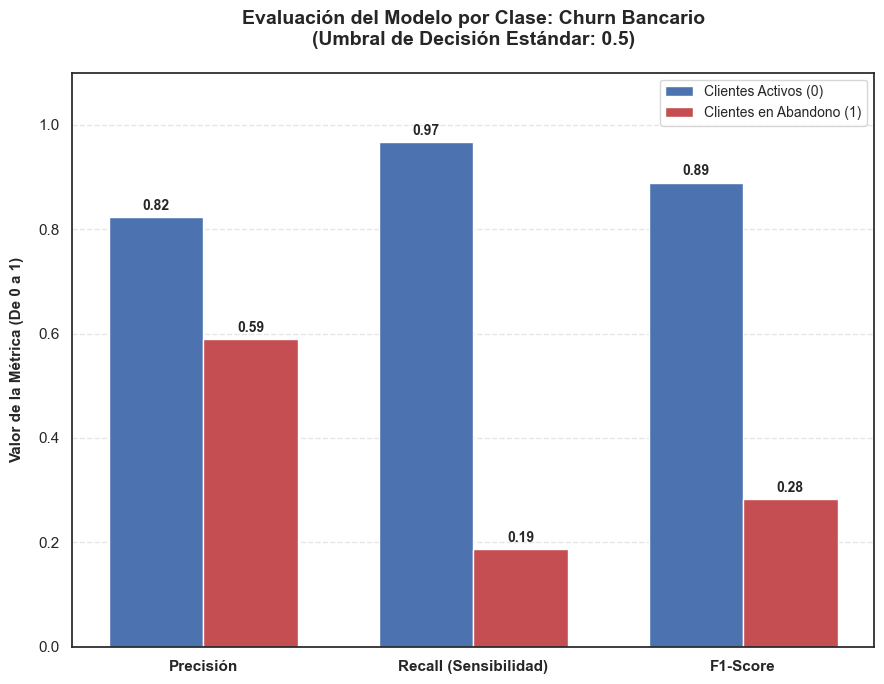

In [35]:
# 1. Definir las métricas reales 
metricas = ['Precisión', 'Recall (Sensibilidad)', 'F1-Score']
# Extraemos los valores de la clave "Activo"
valores_activo = [
    reporte_dict["Activo"]["precision"],
    reporte_dict["Activo"]["recall"],
    reporte_dict["Activo"]["f1-score"]
]

# Extraemos los valores de la clave "Abandono"
valores_abandono = [
    reporte_dict["Abandono"]["precision"],
    reporte_dict["Abandono"]["recall"],
    reporte_dict["Abandono"]["f1-score"]
]

x = np.arange(len(metricas))  # Ubicación de las etiquetas en el eje X
ancho_barra = 0.35            # Ancho de cada barra individual

# 2. Crear el lienzo con tamaño profesional (9x7)
fig, ax = plt.subplots(figsize=(9, 7))

# 3. Dibujar las barras utilizando tu paleta corporativa de turquesas
barra1 = ax.bar(x - ancho_barra/2, valores_activo, ancho_barra, label='Clientes Activos (0)', color='#4C72B0')   
barra2 = ax.bar(x + ancho_barra/2, valores_abandono, ancho_barra, label='Clientes en Abandono (1)', color='#C44E52') 

# 4. Configurar títulos, etiquetas y diseño de los ejes
ax.set_title('Evaluación del Modelo por Clase: Churn Bancario\n(Umbral de Decisión Estándar: 0.5)', fontsize=14, pad=20, weight='bold')
ax.set_ylabel('Valor de la Métrica (De 0 a 1)', fontsize=11, labelpad=10, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, weight='bold')
ax.set_ylim(0, 1.1) # Damos un margen superior para que quepan los números de las etiquetas

# Leyenda elegante en la esquina superior derecha
ax.legend(fontsize=10, loc='upper right', frameon=True)

# Agregar líneas de guía horizontales muy sutiles para facilitar la lectura
ax.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Función automática para colocar el número exacto arriba de cada barra
def agregar_etiquetas(barras):
    for barra in barras:
        alto = barra.get_height()
        ax.annotate(f'{alto:.2f}',
                    xy=(barra.get_x() + barra.get_width() / 2, alto),
                    xytext=(0, 3),  # 3 puntos de desfase vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, weight='bold')

agregar_etiquetas(barra1)
agregar_etiquetas(barra2)

plt.tight_layout()
plt.show()

>Se expone un severo sesgo predictivo hacia la clase mayoritaria (Clientes Activos). El modelo es excelente identificando a quienes se van a quedar (Recall = 0.97), pero sufre de un punto ciego crítico para detectar la fuga: su Recall para la clase de Abandono es de apenas 0.19. Esto significa que operativamente el banco pasaría por alto al 81% de los clientes en riesgo real de irse. El bajo F1-Score resultante (0.28) para la clase objetivo demuestra que el umbral de 0.5 es ineficaz para la estrategia de retención y justifica la necesidad urgente de optimizar el umbral de decisión para priorizar la sensibilidad.


# 7. Conclusión y próximos pasos del Proyecto Integrador
- **Línea base establecida:** dejamos construido y validado el modelo baseline de FinanceGuard (regresión logística). En el conjunto de test (2.000 clientes, 407 abandonos) obtiene ROC-AUC 0,775, PR-AUC 0,479 y F1-Score 0,284 con el umbral por defecto (0.50). En ese umbral prioriza precisión (58,9%) pero tiene bajo alcance (Recall 18,7%); al balancear el peso de las clases, alcanza un Recall del 70,0% y F1-Score de 0,500. Estas métricas son la referencia para el Avance 2.

- **Factores determinantes del churn** (odds ratios; en variables continuas, por cada +1 desvío estándar): la edad (`Age`, OR ≈ 2,10), la residencia en Alemania (`Geography_Germany`, OR ≈ 2,28 frente a Francia) y el saldo en cuenta (`Balance`, OR ≈ 1,17) incrementan significativamente el riesgo de abandono, mientras que la actividad en la plataforma (`IsActiveMember`, OR ≈ 0,36) y el género masculino (`Gender_Male`, OR ≈ 0,59 frente a mujer) reducen la propensión a la baja. `Tenure`, `EstimatedSalary`, `HasCrCard` y `Geography_Spain` no son estadísticamente significativas.

- **Limitación estructural del baseline:** la regresión logística asume una relación lineal en el log-odds y no captura por sí sola relaciones no lineales. Un caso claro es `NumOfProducts`: abandonan el 27,7% de quienes tienen 1 producto, el 7,6% con 2, el 82,7% con 3 y el 100% con 4 (60 clientes), un patrón que un único coeficiente lineal no refleja. Esto motiva probar modelos de ensamble en el Avance 2.
